# Finance Audience Steering with Hidden-State Interventions by MP Aghababa
## www.linkedin.com/in/mpaghababa

This notebook explores a practical question:

**Can we make the same LLM explain the same finance concept differently depending on the stakeholder — without fine-tuning?**

The goal is to steer an open-source transformer model toward three finance communication modes:

- **Retail investor** — plain English, intuition, simple examples
- **Finance analyst** — valuation, accounting, assumptions, sensitivity, working capital
- **CFO / FP&A leader** — planning, liquidity, capital allocation, forecasting, risk

The core idea is not to train three models or build three agents. Instead, we inspect the model internally and learn where these audience styles separate in hidden-state space.

At a high level, the notebook does this:

1. **Loads an instruction-tuned open-source LLM** using Hugging Face Transformers.
2. **Creates a finance topic dataset inside the notebook**, covering concepts such as free cash flow, WACC, credit spreads, duration risk, revenue recognition, and working capital.
3. **Generates three audience-specific explanations per topic**: retail, analyst, and CFO / FP&A.
4. **Extracts hidden states across transformer layers** for each generated response.
5. **Computes audience centroids** in representation space:

$$
\mu_l^{(retail)}, \quad
\mu_l^{(analyst)}, \quad
\mu_l^{(cfo)}
$$

6. **Builds a neutral centroid**:

$$
\mu_l^{(neutral)} =
\frac{
\mu_l^{(retail)} +
\mu_l^{(analyst)} +
\mu_l^{(cfo)}
}{3}
$$

7. **Learns one steering direction per audience**:

$$
d_l^{(mode)} =
\frac{
\mu_l^{(mode)} - \mu_l^{(neutral)}
}{
\|\mu_l^{(mode)} - \mu_l^{(neutral)}\|_2
}
$$

8. **Selects the best transformer layer** using a between-class / within-class separability score.
9. **Applies activation steering at inference time**:

$$
h_l \leftarrow h_l + \alpha d_l^{(mode)}
$$

where:

- $h_l$ is the hidden state at the selected layer
- $d_l^{(mode)}$ is the learned audience direction
- $\alpha$ controls steering strength

This is a representation-level intervention. The model weights are not updated. The steering happens during inference by nudging the hidden-state trajectory toward the target audience mode.

The bigger product idea is simple: enterprise AI should not give the same answer to a CFO, analyst, investor, and board member. They need different levels of abstraction, different framing, and different decision context.

In [1]:
# Cell #1: Install the libraries needed for model loading, quantization, plotting, and analysis.
!pip -q install -U transformers accelerate bitsandbytes sentencepiece pandas numpy matplotlib scikit-learn tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
db-dtypes 1.5.1 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.3 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.4.6 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.3 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.3 which is incompatible.


In [2]:
# Cell: Fix NumPy / Transformers import mismatch in Colab.
!pip uninstall -y numpy
!pip install --no-cache-dir "numpy==1.26.4"
!pip install --no-cache-dir -U transformers accelerate bitsandbytes sentencepiece pandas matplotlib scikit-learn tqdm

Found existing installation: numpy 2.4.6
Uninstalling numpy-2.4.6:
  Successfully uninstalled numpy-2.4.6
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 114.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
db-dtypes 1.5.1 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.3 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompat

In [3]:
# Cell #2: Import libraries and set reproducibility, display, and runtime defaults.
import os
import re
import json
import math
import random
import textwrap
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    set_seed,
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_colwidth", 200)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE: cuda
GPU: Tesla T4


In [4]:
# Cell #3: Define experiment configuration, model choice, dataset size, generation lengths, and steering strength.
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

USE_4BIT = torch.cuda.is_available()

DATASET_SIZE = 20
TEST_SIZE = 5
MAX_NEW_TOKENS_DATA = 80
MAX_NEW_TOKENS_DEMO = 120

# DATASET_SIZE = 60
# TEST_SIZE = 10
# MAX_NEW_TOKENS_DATA = 120
# MAX_NEW_TOKENS_DEMO = 160

DEFAULT_ALPHA = 3.0
ALPHAS_TO_TRY = [0.0, 1.5, 3.0, 4.5]



print("MODEL_NAME:", MODEL_NAME)
print("DATASET_SIZE:", DATASET_SIZE)
print("TEST_SIZE:", TEST_SIZE)

MODEL_NAME: Qwen/Qwen2.5-1.5B-Instruct
DATASET_SIZE: 20
TEST_SIZE: 5


In [5]:
# Cell #4: Load tokenizer and model, using 4-bit quantization on GPU to make Colab runs more reliable.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_kwargs = dict(
    trust_remote_code=True,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
)

if USE_4BIT and torch.cuda.is_available():
    quant_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4",
    )
    model_kwargs["quantization_config"] = quant_config
    model_kwargs["device_map"] = "auto"
else:
    model_kwargs["device_map"] = "auto" if torch.cuda.is_available() else None

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_kwargs)
model.eval()

num_layers = model.config.num_hidden_layers
hidden_size = model.config.hidden_size

print("num_layers:", num_layers)
print("hidden_size:", hidden_size)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

num_layers: 28
hidden_size: 1536


In [6]:
# Cell #5: Add a markdown-like experiment summary so the notebook reads like a technical artifact.
EXPERIMENT_NOTES = """
Finance V2 activation steering notebook

Modes:
- retail investor
- analyst
- CFO / FP&A

Core idea:
For each layer l, estimate mode centroids:
  mu_l^(retail), mu_l^(analyst), mu_l^(cfo)

Define a neutral centroid:
  mu_l^(neutral) = (mu_l^(retail) + mu_l^(analyst) + mu_l^(cfo)) / 3

Define a steering direction for each mode:
  d_l^(mode) = normalize(mu_l^(mode) - mu_l^(neutral))

At inference time:
  h_l <- h_l + alpha * d_l^(mode)

We pick the best steering layer using a between-class / within-class separation score.
"""
print(EXPERIMENT_NOTES)


Finance V2 activation steering notebook

Modes:
- retail investor
- analyst
- CFO / FP&A

Core idea:
For each layer l, estimate mode centroids:
  mu_l^(retail), mu_l^(analyst), mu_l^(cfo)

Define a neutral centroid:
  mu_l^(neutral) = (mu_l^(retail) + mu_l^(analyst) + mu_l^(cfo)) / 3

Define a steering direction for each mode:
  d_l^(mode) = normalize(mu_l^(mode) - mu_l^(neutral))

At inference time:
  h_l <- h_l + alpha * d_l^(mode)

We pick the best steering layer using a between-class / within-class separation score.



In [7]:
# Cell #6: Create a large in-notebook finance topic bank so the dataset is generated entirely inside the notebook.
FINANCE_TOPICS = [
    "free cash flow",
    "discounted cash flow",
    "enterprise value",
    "equity value",
    "working capital",
    "gross margin",
    "operating margin",
    "EBITDA",
    "net income",
    "earnings quality",
    "cash conversion cycle",
    "return on invested capital",
    "weighted average cost of capital",
    "duration risk",
    "interest rate sensitivity",
    "yield curve inversion",
    "credit spreads",
    "default risk",
    "liquidity risk",
    "solvency risk",
    "beta",
    "cost of equity",
    "capital structure",
    "share dilution",
    "buybacks",
    "dividends",
    "retained earnings",
    "debt covenants",
    "bridge financing",
    "leveraged buyout",
    "accretion and dilution",
    "customer acquisition cost",
    "lifetime value",
    "gross retention",
    "net revenue retention",
    "deferred revenue",
    "revenue recognition",
    "cohort analysis",
    "unit economics",
    "burn multiple",
    "gross merchandise value",
    "take rate",
    "inventory turnover",
    "days sales outstanding",
    "days payable outstanding",
    "bad debt expense",
    "allowance for credit losses",
    "impairment charges",
    "goodwill",
    "intangible assets",
    "capex",
    "opex",
    "depreciation",
    "amortization",
    "stock-based compensation",
    "adjusted EBITDA",
    "segment reporting",
    "foreign exchange exposure",
    "hedging",
    "commodity exposure",
    "floating-rate debt",
    "fixed-rate debt",
    "refinancing risk",
    "terminal value",
    "comparable company analysis",
    "precedent transactions",
    "sensitivity analysis",
    "scenario analysis",
    "downside case",
    "base case",
    "upside case",
    "gross leverage",
    "net leverage",
    "interest coverage ratio",
    "current ratio",
    "quick ratio",
    "book value",
    "tangible book value",
    "price to earnings ratio",
    "enterprise value to EBITDA",
    "price to sales ratio",
    "return on equity",
    "operating cash flow",
    "capital allocation",
    "rule of 40",
    "gross profit",
    "contribution margin",
    "fixed costs",
    "variable costs",
    "cash runway",
    "treasury management",
    "budget variance",
    "forecast accuracy",
    "rolling forecast",
    "annual recurring revenue",
    "monthly recurring revenue",
    "churn",
    "gross profit retention",
    "cost of goods sold",
    "working capital optimization",
    "accounts receivable factoring",
    "days inventory outstanding",
    "covenant headroom",
    "earnings per share",
    "fully diluted shares",
    "bridge from EBITDA to free cash flow",
    "valuation multiple compression",
    "operating leverage",
    "price elasticity",
    "return on assets",
    "asset turnover",
    "restructuring charges",
]

assert len(FINANCE_TOPICS) >= DATASET_SIZE + TEST_SIZE
print("Total finance topics:", len(FINANCE_TOPICS))

Total finance topics: 112


In [8]:
# Cell #7: Define prompt templates for the three finance audiences while keeping the topic itself fixed.
SYSTEM_PROMPT = (
    "You are a precise financial explainer. "
    "Be accurate, educational, and avoid personalized investment advice. "
    "Adapt the explanation to the requested audience."
)

RETAIL_TEMPLATE = """Explain {topic} for a retail investor.
Requirements:
- Use plain English.
- Avoid jargon unless you define it.
- Focus on intuition and why it matters.
- Give one simple example if useful.
- 2 to 4 short paragraphs.
- Do not give personalized investment advice.
"""

ANALYST_TEMPLATE = """Explain {topic} for a finance analyst.
Requirements:
- Use technically precise language.
- Mention formulas, drivers, and tradeoffs where relevant.
- Mention valuation or accounting implications where relevant.
- Be concise but information-dense.
- 2 to 4 short paragraphs.
"""

CFO_TEMPLATE = """Explain {topic} for a CFO or FP&A leader.
Requirements:
- Focus on business implications, controllable levers, and planning decisions.
- Mention cash flow, budgeting, forecasting, capital allocation, or risk management where relevant.
- Use executive-level but technically sound language.
- Be concise and structured.
- 2 to 4 short paragraphs.
"""

In [9]:
# Cell #8: Build chat-formatted prompts using the tokenizer's chat template when available.
def build_messages(user_prompt: str):
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt},
    ]

def render_chat(user_prompt: str):
    messages = build_messages(user_prompt)
    try:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )
    except Exception:
        return f"System: {SYSTEM_PROMPT}\nUser: {user_prompt}\nAssistant:"

In [10]:
# Cell #9: Implement deterministic generation so style differences come from the audience prompt rather than sampling noise.
@torch.no_grad()
def generate_response(user_prompt: str, max_new_tokens: int = 140):
    prompt_text = render_chat(user_prompt)
    inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)

    output_ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        temperature=None,
        top_p=None,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

    prompt_len = inputs["input_ids"].shape[1]
    gen_ids = output_ids[0, prompt_len:]
    response_text = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    return {
        "prompt_text": prompt_text,
        "response_text": response_text,
    }

In [11]:
# Cell 10 — Generate, save, and resume the finance audience dataset without losing progress.
DATASET_CACHE_PATH = "finance_v2_dataset_cache.json"

all_topics = FINANCE_TOPICS.copy()
random.shuffle(all_topics)

train_topics = all_topics[:DATASET_SIZE]
test_topics = all_topics[DATASET_SIZE:DATASET_SIZE + TEST_SIZE]

if os.path.exists(DATASET_CACHE_PATH):
    print(f"Found existing cache: {DATASET_CACHE_PATH}")
    cached_df = pd.read_json(DATASET_CACHE_PATH)
    rows = cached_df.to_dict(orient="records")
    completed_topics = set(cached_df["topic"].tolist())
    print(f"Loaded {len(rows)} completed topics from cache.")
else:
    rows = []
    completed_topics = set()
    print("No cache found. Starting generation from scratch.")

remaining_topics = [t for t in train_topics if t not in completed_topics]

print(f"Target topics: {len(train_topics)}")
print(f"Completed topics: {len(completed_topics)}")
print(f"Remaining topics: {len(remaining_topics)}")
print(f"Total remaining generations: {len(remaining_topics) * 3}")

for topic in tqdm(remaining_topics, desc="Building finance audience dataset"):
    retail_prompt = RETAIL_TEMPLATE.format(topic=topic)
    analyst_prompt = ANALYST_TEMPLATE.format(topic=topic)
    cfo_prompt = CFO_TEMPLATE.format(topic=topic)

    retail_out = generate_response(retail_prompt, max_new_tokens=MAX_NEW_TOKENS_DATA)
    analyst_out = generate_response(analyst_prompt, max_new_tokens=MAX_NEW_TOKENS_DATA)
    cfo_out = generate_response(cfo_prompt, max_new_tokens=MAX_NEW_TOKENS_DATA)

    rows.append({
        "topic": topic,
        "retail_user_prompt": retail_prompt,
        "analyst_user_prompt": analyst_prompt,
        "cfo_user_prompt": cfo_prompt,
        "retail_prompt_text": retail_out["prompt_text"],
        "analyst_prompt_text": analyst_out["prompt_text"],
        "cfo_prompt_text": cfo_out["prompt_text"],
        "retail_response": retail_out["response_text"],
        "analyst_response": analyst_out["response_text"],
        "cfo_response": cfo_out["response_text"],
    })

    # Save after every completed topic.
    pd.DataFrame(rows).to_json(DATASET_CACHE_PATH, orient="records", indent=2)

df = pd.DataFrame(rows)
print("Dataset shape:", df.shape)
print(f"Saved dataset to {DATASET_CACHE_PATH}")
df.head(3)

No cache found. Starting generation from scratch.
Target topics: 20
Completed topics: 0
Remaining topics: 20
Total remaining generations: 60


Building finance audience dataset:   0%|          | 0/20 [00:00<?, ?it/s]

Dataset shape: (20, 10)
Saved dataset to finance_v2_dataset_cache.json


,topic,retail_user_prompt,analyst_user_prompt,cfo_user_prompt,retail_prompt_text,analyst_prompt_text,cfo_prompt_text,retail_response,analyst_response,cfo_response
0,yield curve inversion,Explain yield curve inversion for a retail investor.\nRequirements:\n- Use plain English.\n- Avoid jargon unless you define it.\n- Focus on intuition and why it matters.\n- Give one simple example...,"Explain yield curve inversion for a finance analyst.\nRequirements:\n- Use technically precise language.\n- Mention formulas, drivers, and tradeoffs where relevant.\n- Mention valuation or account...","Explain yield curve inversion for a CFO or FP&A leader.\nRequirements:\n- Focus on business implications, controllable levers, and planning decisions.\n- Mention cash flow, budgeting, forecasting,...","<|im_start|>system\nYou are a precise financial explainer. Be accurate, educational, and avoid personalized investment advice. Adapt the explanation to the requested audience.<|im_end|>\n<|im_star...","<|im_start|>system\nYou are a precise financial explainer. Be accurate, educational, and avoid personalized investment advice. Adapt the explanation to the requested audience.<|im_end|>\n<|im_star...","<|im_start|>system\nYou are a precise financial explainer. Be accurate, educational, and avoid personalized investment advice. Adapt the explanation to the requested audience.<|im_end|>\n<|im_star...","When an economy is doing well, investors often expect higher returns from their investments. This expectation creates what's called a ""yield curve,"" which is essentially a graph showing how much i...",Yield curve inversion is a phenomenon in finance where long-term interest rates fall below short-term interest rates. This occurs when investors demand higher returns on longer-term investments co...,"For a CFO or FP&A leader, understanding yield curve inversion is crucial as it can significantly impact various aspects of your company's operations and strategic planning.\n\nYield curve inversio..."
1,impairment charges,Explain impairment charges for a retail investor.\nRequirements:\n- Use plain English.\n- Avoid jargon unless you define it.\n- Focus on intuition and why it matters.\n- Give one simple example if...,"Explain impairment charges for a finance analyst.\nRequirements:\n- Use technically precise language.\n- Mention formulas, drivers, and tradeoffs where relevant.\n- Mention valuation or accounting...","Explain impairment charges for a CFO or FP&A leader.\nRequirements:\n- Focus on business implications, controllable levers, and planning decisions.\n- Mention cash flow, budgeting, forecasting, ca...","<|im_start|>system\nYou are a precise financial explainer. Be accurate, educational, and avoid personalized investment advice. Adapt the explanation to the requested audience.<|im_end|>\n<|im_star...","<|im_start|>system\nYou are a precise financial explainer. Be accurate, educational, and avoid personalized investment advice. Adapt the explanation to the requested audience.<|im_end|>\n<|im_star...","<|im_start|>system\nYou are a precise financial explainer. Be accurate, educational, and avoid personalized investment advice. Adapt the explanation to the requested audience.<|im_end|>\n<|im_star...",Impairment charges in finance refer to situations where an asset's value falls below its carrying amount on the balance sheet. This happens when there is a significant decline in the asset's marke...,Impairment charges in finance refer to the write-down of an asset's value when it is determined that its carrying amount exceeds its recoverable amount. This process involves assessing whether the...,"Impairment charges represent a significant accounting entry that reflects the decline in value of an asset below its carrying amount. For a CFO or FP&A leader, understanding these charges is cruci..."
2,accretion and dilution,Explain accretion and dilution for a retail investor.\nRequirements:\n- Use plain English.\n- Avoid jargon unless you define it.\n- Focus o

In [12]:
# Cell #11: Preview a few generated examples to make sure the three finance modes are visibly different before steering.
for i in range(2):
    row = df.iloc[i]
    print("=" * 110)
    print("TOPIC:", row["topic"])

    print("\nRETAIL:\n")
    print(textwrap.fill(row["retail_response"][:1000], width=100))

    print("\nANALYST:\n")
    print(textwrap.fill(row["analyst_response"][:1000], width=100))

    print("\nCFO / FP&A:\n")
    print(textwrap.fill(row["cfo_response"][:1000], width=100))
    print()

TOPIC: yield curve inversion

RETAIL:

When an economy is doing well, investors often expect higher returns from their investments. This
expectation creates what's called a "yield curve," which is essentially a graph showing how much
interest rates change with different levels of risk.  Imagine a seesaw where each end represents two
types of investments: low-risk (like savings accounts) and high-risk (like stocks). The middle point
shows the average return expected by

ANALYST:

Yield curve inversion is a phenomenon in finance where long-term interest rates fall below short-
term interest rates. This occurs when investors demand higher returns on longer-term investments
compared to shorter-term ones. The yield curve typically slopes upward, indicating that riskier
assets (like stocks) offer higher yields than safer assets (like bonds).  The formula for the yield
curve can be expressed as:  \[ \text{Long

CFO / FP&A:

For a CFO or FP&A leader, understanding yield curve inversion is cruc

In [13]:
# Cell #12: Extract per-layer mean hidden states over response tokens for a prompt-plus-response pair.
@torch.no_grad()
def get_mean_response_hidden_states(prompt_text: str, response_text: str):
    full_text = prompt_text + response_text

    enc_full = tokenizer(full_text, return_tensors="pt", add_special_tokens=False).to(model.device)
    enc_prompt = tokenizer(prompt_text, return_tensors="pt", add_special_tokens=False).to(model.device)

    prompt_len = enc_prompt["input_ids"].shape[1]
    full_len = enc_full["input_ids"].shape[1]

    outputs = model(
        **enc_full,
        output_hidden_states=True,
        use_cache=False,
    )

    hidden_states = outputs.hidden_states

    if full_len <= prompt_len:
        raise ValueError("No response tokens found.")

    layer_means = []
    for layer_idx in range(1, len(hidden_states)):
        hs = hidden_states[layer_idx][0, prompt_len:full_len, :]
        layer_means.append(hs.mean(dim=0).float().detach().cpu())

    return torch.stack(layer_means, dim=0)  # [L, H]

In [14]:
# Cell 13 — Extract or load hidden-state tensors for all three finance audiences.
HIDDEN_CACHE_PATH = "finance_v2_hidden_states.pt"

if os.path.exists(HIDDEN_CACHE_PATH):
    print(f"Loading cached hidden states from {HIDDEN_CACHE_PATH}")
    cache = torch.load(HIDDEN_CACHE_PATH, map_location="cpu")
    retail_hiddens = cache["retail_hiddens"]
    analyst_hiddens = cache["analyst_hiddens"]
    cfo_hiddens = cache["cfo_hiddens"]
else:
    print("No hidden-state cache found. Extracting hidden states...")

    retail_hiddens = []
    analyst_hiddens = []
    cfo_hiddens = []

    for _, row in tqdm(df.iterrows(), total=len(df), desc="Extracting hidden states"):
        retail_hiddens.append(get_mean_response_hidden_states(row["retail_prompt_text"], row["retail_response"]))
        analyst_hiddens.append(get_mean_response_hidden_states(row["analyst_prompt_text"], row["analyst_response"]))
        cfo_hiddens.append(get_mean_response_hidden_states(row["cfo_prompt_text"], row["cfo_response"]))

    retail_hiddens = torch.stack(retail_hiddens, dim=0)
    analyst_hiddens = torch.stack(analyst_hiddens, dim=0)
    cfo_hiddens = torch.stack(cfo_hiddens, dim=0)

    torch.save({
        "retail_hiddens": retail_hiddens,
        "analyst_hiddens": analyst_hiddens,
        "cfo_hiddens": cfo_hiddens,
    }, HIDDEN_CACHE_PATH)

    print(f"Saved hidden states to {HIDDEN_CACHE_PATH}")

print("retail_hiddens:", tuple(retail_hiddens.shape))
print("analyst_hiddens:", tuple(analyst_hiddens.shape))
print("cfo_hiddens:", tuple(cfo_hiddens.shape))

No hidden-state cache found. Extracting hidden states...


Extracting hidden states:   0%|          | 0/20 [00:00<?, ?it/s]

Saved hidden states to finance_v2_hidden_states.pt
retail_hiddens: (20, 28, 1536)
analyst_hiddens: (20, 28, 1536)
cfo_hiddens: (20, 28, 1536)


In [15]:
# Cell #14: Estimate per-layer centroids for each audience and define a neutral centroid across the three classes.
def l2_normalize(x: torch.Tensor, eps: float = 1e-12):
    return x / (x.norm(dim=-1, keepdim=True) + eps)

mu_retail = retail_hiddens.mean(dim=0)   # [L, H]
mu_analyst = analyst_hiddens.mean(dim=0)
mu_cfo = cfo_hiddens.mean(dim=0)

mu_neutral = (mu_retail + mu_analyst + mu_cfo) / 3.0

dir_retail = l2_normalize(mu_retail - mu_neutral)
dir_analyst = l2_normalize(mu_analyst - mu_neutral)
dir_cfo = l2_normalize(mu_cfo - mu_neutral)

print("dir_retail:", tuple(dir_retail.shape))
print("dir_analyst:", tuple(dir_analyst.shape))
print("dir_cfo:", tuple(dir_cfo.shape))

dir_retail: (28, 1536)
dir_analyst: (28, 1536)
dir_cfo: (28, 1536)


In [16]:
# Cell #15: Score each layer with a simple Fisher-style separation metric to pick the most informative steering layer.
layer_stats = []

for layer_idx in range(num_layers):
    class_means = torch.stack([
        mu_retail[layer_idx],
        mu_analyst[layer_idx],
        mu_cfo[layer_idx],
    ], dim=0)  # [3, H]

    neutral = mu_neutral[layer_idx]  # [H]
    between = ((class_means - neutral.unsqueeze(0)) ** 2).sum(dim=1).mean().item()

    within_retail = ((retail_hiddens[:, layer_idx, :] - mu_retail[layer_idx]) ** 2).sum(dim=1).mean().item()
    within_analyst = ((analyst_hiddens[:, layer_idx, :] - mu_analyst[layer_idx]) ** 2).sum(dim=1).mean().item()
    within_cfo = ((cfo_hiddens[:, layer_idx, :] - mu_cfo[layer_idx]) ** 2).sum(dim=1).mean().item()
    within = (within_retail + within_analyst + within_cfo) / 3.0

    fisher_score = between / (within + 1e-8)

    # also record centroid-distance summary for interpretability
    dist_ra = torch.norm(mu_retail[layer_idx] - mu_analyst[layer_idx]).item()
    dist_rc = torch.norm(mu_retail[layer_idx] - mu_cfo[layer_idx]).item()
    dist_ac = torch.norm(mu_analyst[layer_idx] - mu_cfo[layer_idx]).item()

    layer_stats.append({
        "layer": layer_idx,
        "fisher_score": fisher_score,
        "dist_retail_analyst": dist_ra,
        "dist_retail_cfo": dist_rc,
        "dist_analyst_cfo": dist_ac,
        "avg_centroid_dist": (dist_ra + dist_rc + dist_ac) / 3.0,
    })

layer_df = pd.DataFrame(layer_stats).sort_values("fisher_score", ascending=False).reset_index(drop=True)
layer_df.head(10)

,layer,fisher_score,dist_retail_analyst,dist_retail_cfo,dist_analyst_cfo,avg_centroid_dist
0,27,0.484955,52.229824,46.903011,31.635221,43.589352
1,19,0.425602,16.695274,17.548515,12.472151,15.571980
2,18,0.394509,14.364037,15.272051,10.729940,13.455343
3,21,0.372360,27.280827,29.132458,18.192982,24.868755
4,17,0.367878,12.982658,13.912484,9.866391,12.253845
5,22,0.342392,30.936993,32.862202,21.001675,28.266956
6,24,0.333848,42.144676,44.884548,28.470943,38.500056
7,26,0.330192,49.360931,50.939682,33.499187,44.599934
8,25,0.328012,46.216881,48.200508,31.219145,41.878845
9,16,0.326136,11.316760,12.114345,9.283852,10.904985


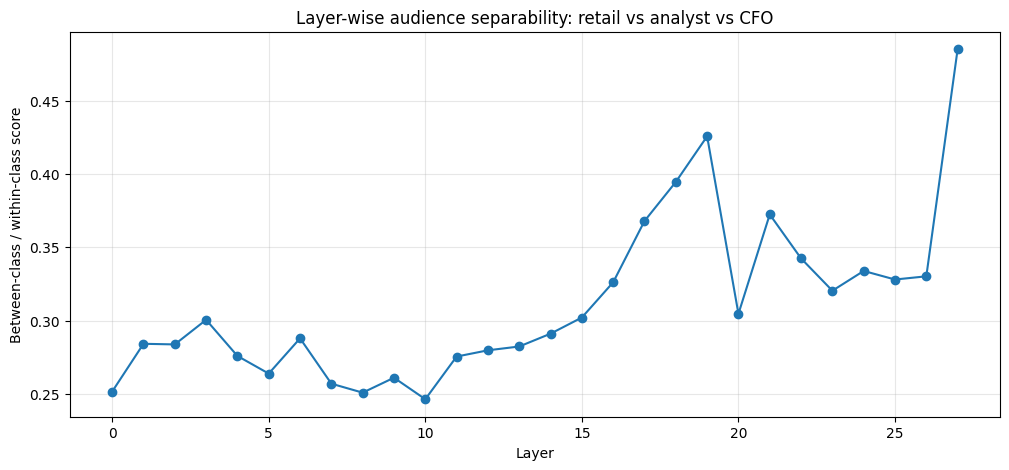

Chosen steering layer: 27
   layer  fisher_score  dist_retail_analyst  dist_retail_cfo  \
0     27      0.484955            52.229824        46.903011   

   dist_analyst_cfo  avg_centroid_dist  
0         31.635221          43.589352  


In [17]:
# Cell #16: Plot layer quality so the notebook shows a principled layer selection step instead of a random choice.
plot_df = pd.DataFrame(layer_stats).sort_values("layer")

plt.figure(figsize=(12, 5))
plt.plot(plot_df["layer"], plot_df["fisher_score"], marker="o")
plt.xlabel("Layer")
plt.ylabel("Between-class / within-class score")
plt.title("Layer-wise audience separability: retail vs analyst vs CFO")
plt.grid(True, alpha=0.3)
plt.show()

best_layer = int(layer_df.iloc[0]["layer"])
print("Chosen steering layer:", best_layer)
print(layer_df[layer_df["layer"] == best_layer])

In [18]:
# Cell #17: Show the top candidate layers for transparency and later tuning if you want to compare interventions.
layer_df.head(8)

,layer,fisher_score,dist_retail_analyst,dist_retail_cfo,dist_analyst_cfo,avg_centroid_dist
0,27,0.484955,52.229824,46.903011,31.635221,43.589352
1,19,0.425602,16.695274,17.548515,12.472151,15.571980
2,18,0.394509,14.364037,15.272051,10.729940,13.455343
3,21,0.372360,27.280827,29.132458,18.192982,24.868755
4,17,0.367878,12.982658,13.912484,9.866391,12.253845
5,22,0.342392,30.936993,32.862202,21.001675,28.266956
6,24,0.333848,42.144676,44.884548,28.470943,38.500056
7,26,0.330192,49.360931,50.939682,33.499187,44.599934


In [19]:
# Cell #18: Implement a generic activation hook that adds a steering vector at one transformer block during generation.
class ActivationSteerer:
    def __init__(self, model, layer_idx: int, direction: torch.Tensor, alpha: float):
        self.model = model
        self.layer_idx = layer_idx
        self.direction = direction.detach().to(model.device)
        self.alpha = alpha
        self.hook = None

    def _hook_fn(self, module, inputs, output):
        if isinstance(output, tuple):
            hidden = output[0]
            rest = output[1:]
            steered = hidden + self.alpha * self.direction.view(1, 1, -1).to(hidden.dtype)
            return (steered, *rest)
        else:
            return output + self.alpha * self.direction.view(1, 1, -1).to(output.dtype)

    def __enter__(self):
        target_module = model.model.layers[self.layer_idx]
        self.hook = target_module.register_forward_hook(self._hook_fn)
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        if self.hook is not None:
            self.hook.remove()
            self.hook = None

In [20]:
# Cell #19: Map each audience mode to its learned direction at the chosen layer.
mode_to_direction = {
    "retail": dir_retail,
    "analyst": dir_analyst,
    "cfo": dir_cfo,
}
print(mode_to_direction.keys())

dict_keys(['retail', 'analyst', 'cfo'])


In [21]:
# Cell #20: Generate a response with optional finance audience steering applied at the selected layer.
@torch.no_grad()
def generate_with_steering(user_prompt: str, mode: str = None, alpha: float = 0.0, layer_idx: int = None, max_new_tokens: int = 180):
    if layer_idx is None:
        layer_idx = best_layer

    prompt_text = render_chat(user_prompt)
    inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)

    if mode is None or abs(alpha) < 1e-9:
        out_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    else:
        direction = mode_to_direction[mode][layer_idx]
        with ActivationSteerer(model, layer_idx, direction, alpha):
            out_ids = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                temperature=None,
                top_p=None,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

    prompt_len = inputs["input_ids"].shape[1]
    gen_ids = out_ids[0, prompt_len:]
    return tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

In [22]:
# Cell #21: Run a quick sanity check on one neutral finance concept across all three audience modes.
neutral_prompt = "Explain free cash flow."

print("=" * 100)
print("BASE:\n")
print(textwrap.fill(generate_with_steering(neutral_prompt, mode=None, alpha=0.0, max_new_tokens=140), width=100))

for mode in ["retail", "analyst", "cfo"]:
    print("\n" + "=" * 100)
    print(f"{mode.upper()} STEERED:\n")
    print(textwrap.fill(generate_with_steering(neutral_prompt, mode=mode, alpha=DEFAULT_ALPHA, max_new_tokens=140), width=100))

BASE:

Free Cash Flow (FCF) is a key metric used in finance and investing that measures how much cash a
company generates after accounting for capital expenditures. It's essentially the amount of money
left over from a company's operating activities after it has paid for its investments.  Here’s a
step-by-step breakdown:  1. **Operating Activities**: This includes all revenues generated by the
core business operations minus expenses such as cost of goods sold, selling, general, and
administrative costs, depreciation, and amortization.  2. **Capital Expenditures**: These are
investments made by the company in long-term assets like property, plant, and equipment. They are
subtracted because they represent out-of-pocket expenses that reduce

RETAIL STEERED:

Free Cash Flow (FCF) is a key metric used in finance and investing that measures how much cash a
company generates after accounting for capital expenditures. It's essentially the amount of money
left over from a company's operating ac

In [23]:
# Cell #22: Define lightweight finance-style metrics so we can quantify shifts across the three audiences.
RETAIL_WORDS = {
    "simple", "basically", "means", "think", "like", "easy", "plain", "example", "why", "important"
}
ANALYST_WORDS = {
    "valuation", "multiple", "margin", "cash flow", "ebitda", "discount rate", "sensitivity",
    "assumption", "earnings", "capital structure", "working capital", "dilution", "return"
}
CFO_WORDS = {
    "budget", "forecast", "planning", "liquidity", "runway", "capital allocation", "cash management",
    "headroom", "operating plan", "scenario", "risk", "board", "efficiency", "levers"
}

def simple_word_tokenize(text: str):
    return re.findall(r"[A-Za-z0-9\-]+", text.lower())

def phrase_count(text: str, phrases):
    lower = text.lower()
    return sum(lower.count(p) for p in phrases)

def finance_metrics(text: str):
    words = simple_word_tokenize(text)
    word_count = len(words)
    sentence_count = max(1, len(re.findall(r"[.!?]+", text)))
    avg_sentence_len = word_count / sentence_count if sentence_count else word_count

    retail_hits = phrase_count(text, RETAIL_WORDS)
    analyst_hits = phrase_count(text, ANALYST_WORDS)
    cfo_hits = phrase_count(text, CFO_WORDS)

    return {
        "word_count": word_count,
        "sentence_count": sentence_count,
        "avg_sentence_len": avg_sentence_len,
        "retail_vocab_hits": retail_hits,
        "analyst_vocab_hits": analyst_hits,
        "cfo_vocab_hits": cfo_hits,
    }

def round_metrics(d):
    return {k: round(v, 4) if isinstance(v, float) else v for k, v in d.items()}

In [24]:
# Cell #23: Prepare held-out neutral prompts that the steering directions did not see during training.
eval_prompts = [f"Explain {topic}." for topic in test_topics]
eval_prompts[:5]

['Explain floating-rate debt.',
 'Explain commodity exposure.',
 'Explain valuation multiple compression.',
 'Explain downside case.',
 'Explain net leverage.']

In [25]:
# Cell #24: Generate base and three steered outputs on unseen finance prompts and collect their metrics.
eval_rows = []

for prompt in tqdm(eval_prompts, desc="Evaluating held-out prompts"):
    base_text = generate_with_steering(prompt, mode=None, alpha=0.0, max_new_tokens=MAX_NEW_TOKENS_DEMO)
    retail_text = generate_with_steering(prompt, mode="retail", alpha=DEFAULT_ALPHA, max_new_tokens=MAX_NEW_TOKENS_DEMO)
    analyst_text = generate_with_steering(prompt, mode="analyst", alpha=DEFAULT_ALPHA, max_new_tokens=MAX_NEW_TOKENS_DEMO)
    cfo_text = generate_with_steering(prompt, mode="cfo", alpha=DEFAULT_ALPHA, max_new_tokens=MAX_NEW_TOKENS_DEMO)

    eval_rows.append({
        "prompt": prompt,
        "base_text": base_text,
        "retail_text": retail_text,
        "analyst_text": analyst_text,
        "cfo_text": cfo_text,
        "base_metrics": finance_metrics(base_text),
        "retail_metrics": finance_metrics(retail_text),
        "analyst_metrics": finance_metrics(analyst_text),
        "cfo_metrics": finance_metrics(cfo_text),
    })

eval_df = pd.DataFrame(eval_rows)
print(eval_df.shape)
eval_df.head(3)

Evaluating held-out prompts:   0%|          | 0/5 [00:00<?, ?it/s]

(5, 9)


,prompt,base_text,retail_text,analyst_text,cfo_text,base_metrics,retail_metrics,analyst_metrics,cfo_metrics
0,Explain floating-rate debt.,"Floating-rate debt is a type of financial instrument where the interest rate on the loan or bond adjusts periodically based on an external benchmark, such as LIBOR (London Interbank Offered Rate)....","Floating-rate debt is a type of loan or bond where the interest rate changes based on an external benchmark, typically a market index like the U.S. Treasury yield curve. This means that instead of...",Floating-rate debt is a type of financial instrument where the interest rate on the loan or bond adjusts periodically based on an agreed-upon benchmark interest rate. This feature allows investors...,"Floating-rate debt is a type of financial instrument where the interest rate on the loan or bond adjusts periodically based on an external benchmark, such as LIBOR (London Interbank Offered Rate)....","{'word_count': 103, 'sentence_count': 4, 'avg_sentence_len': 25.75, 'retail_vocab_hits': 1, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}","{'word_count': 99, 'sentence_count': 8, 'avg_sentence_len': 12.375, 'retail_vocab_hits': 2, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}","{'word_count': 99, 'sentence_count': 6, 'avg_sentence_len': 16.5, 'retail_vocab_hits': 1, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}","{'word_count': 103, 'sentence_count': 4, 'avg_sentence_len': 25.75, 'retail_vocab_hits': 1, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}"
1,Explain commodity exposure.,"Commodity exposure refers to how much an investor or company is exposed to changes in prices of commodities such as oil, gold, copper, wheat, corn, soybeans, natural gas, and others. It's like bei...","Commodity exposure refers to how much an investor or company is exposed to changes in prices of commodities such as oil, gold, copper, wheat, corn, soybeans, natural gas, and others. It's like bei...","Commodity exposure refers to how sensitive an asset or portfolio is to changes in the prices of commodities such as oil, gold, copper, wheat, and other raw materials. When you invest in commoditie...","Commodity exposure refers to how sensitive an asset or portfolio is to changes in the prices of commodities such as oil, gold, copper, wheat, and other raw materials. When you invest in commoditie...","{'word_count': 100, 'sentence_count': 3, 'avg_sentence_len': 33.333333333333336, 'retail_vocab_hits': 3, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}","{'word_count': 100, 'sentence_count': 3, 'avg_sentence_len': 33.333333333333336, 'retail_vocab_hits': 4, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}","{'word_count': 98, 'sentence_count': 4, 'avg_sentence_len': 24.5, 'retail_vocab_hits': 1, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}","{'word_count': 90, 'sentence_count': 6, 'avg_sentence_len': 15.0, 'retail_vocab_hits': 1, 'analyst_vocab_hits': 0, 'cfo_vocab_hits': 0}"
2,Explain valuation multiple compression.,Valuation multiples compression refers to a situation where the price of a company's stock or its market value is lower than what analysts expect based on historical data or industry norms. This o...,Valuation multiples compression refers to a situation where the price of a company's stock or its market value is lower than what analysts expect based on historical data or industry norms. This o...,Valuation multiples compression refers to a situation where the price of a company's stock or its market value decreases relative to its earnings per share (EPS) over time. This phenomenon occurs ...,Valuation multiples compression refers to a situation where the price of a company's stock or its market value is lower than what analysts expect based on historical data or industry norms. This o...,"{'word_count': 103, 'sentence_count': 4, 'avg_sentence_len': 25.75, 'retail_vocab_hits': 1, 'analyst_vocab_hits': 4, 'cfo_vocab_hits': 0}","{'word_count': 98, 'sentence_count': 5, 'avg_sentence_len': 19.6, 'retail_vocab_hits': 1, 'anal

In [26]:
# Cell #25: Summarize average metric movement by audience mode to show measurable style shifts on unseen prompts.
summary_rows = []

for mode in ["base", "retail", "analyst", "cfo"]:
    metric_list = eval_df[f"{mode}_metrics"].tolist()
    keys = metric_list[0].keys()
    agg = {k: float(np.mean([m[k] for m in metric_list])) for k in keys}
    agg["mode"] = mode
    summary_rows.append(agg)

summary_df = pd.DataFrame(summary_rows)[
    ["mode", "word_count", "sentence_count", "avg_sentence_len", "retail_vocab_hits", "analyst_vocab_hits", "cfo_vocab_hits"]
]
summary_df.round(4)

,mode,word_count,sentence_count,avg_sentence_len,retail_vocab_hits,analyst_vocab_hits,cfo_vocab_hits
0,base,101.4,4.6,23.8981,1.0,0.8,0.6
1,retail,99.8,5.8,19.7017,1.4,1.0,0.6
2,analyst,100.6,4.6,22.4700,1.0,1.4,0.8
3,cfo,99.8,4.4,24.0600,1.2,0.8,0.8


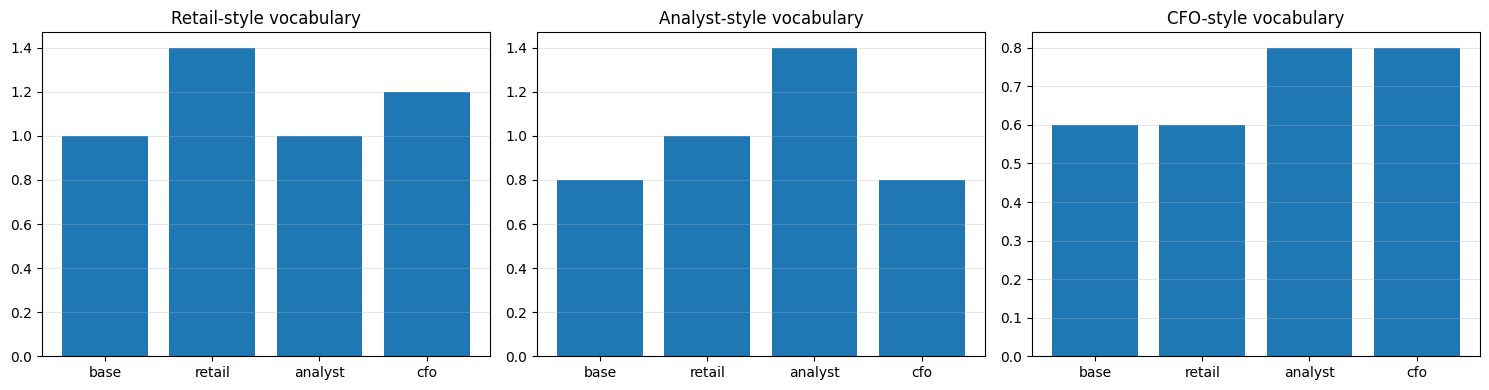

In [27]:
# Cell #26: Plot audience-specific vocabulary signals so the notebook has compact quantitative evidence.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(summary_df["mode"], summary_df["retail_vocab_hits"])
axes[0].set_title("Retail-style vocabulary")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(summary_df["mode"], summary_df["analyst_vocab_hits"])
axes[1].set_title("Analyst-style vocabulary")
axes[1].grid(axis="y", alpha=0.3)

axes[2].bar(summary_df["mode"], summary_df["cfo_vocab_hits"])
axes[2].set_title("CFO-style vocabulary")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Cell #27: Print several held-out examples side by side so the notebook has strong qualitative demo outputs.
for i in range(min(4, len(eval_df))):
    row = eval_df.iloc[i]
    print("=" * 120)
    print("PROMPT:", row["prompt"])

    print("\nBASE:\n")
    print(textwrap.fill(row["base_text"][:1200], width=110))

    print("\nRETAIL STEERED:\n")
    print(textwrap.fill(row["retail_text"][:1200], width=110))

    print("\nANALYST STEERED:\n")
    print(textwrap.fill(row["analyst_text"][:1200], width=110))

    print("\nCFO STEERED:\n")
    print(textwrap.fill(row["cfo_text"][:1200], width=110))
    print()

PROMPT: Explain floating-rate debt.

BASE:

Floating-rate debt is a type of financial instrument where the interest rate on the loan or bond adjusts
periodically based on an external benchmark, such as LIBOR (London Interbank Offered Rate). This feature
allows investors to benefit from changes in market rates without having to actively manage their investments.
Here’s how it works:  1. **Interest Rate Adjustment**: The interest rate on the loan or bond is linked to a
specific index that fluctuates over time. For example, if you have a floating-rate note, your interest payment
will change according to the current value of this index at the end of each quarter

RETAIL STEERED:

Floating-rate debt is a type of loan or bond where the interest rate changes based on an external benchmark,
typically a market index like the U.S. Treasury yield curve. This means that instead of having a fixed
interest rate throughout the term of the loan or bond, the borrower pays a variable amount.  Here’s how

In [29]:
# Cell #28: Save the learned finance steering artifact and generated dataset so the notebook is reproducible and reusable.
artifact = {
    "model_name": MODEL_NAME,
    "best_layer": int(best_layer),
    "default_alpha": float(DEFAULT_ALPHA),
    "fisher_scores": {str(int(r["layer"])): float(r["fisher_score"]) for _, r in pd.DataFrame(layer_stats).iterrows()},
    "dir_retail_best_layer": dir_retail[best_layer].tolist(),
    "dir_analyst_best_layer": dir_analyst[best_layer].tolist(),
    "dir_cfo_best_layer": dir_cfo[best_layer].tolist(),
}

with open("finance_v2_steering_artifact.json", "w") as f:
    json.dump(artifact, f)

with open("finance_v2_dataset.json", "w") as f:
    json.dump(df.to_dict(orient="records"), f)

print("Saved:")
print("- finance_v2_steering_artifact.json")
print("- finance_v2_dataset.json")

Saved:
- finance_v2_steering_artifact.json
- finance_v2_dataset.json


In [30]:
# Cell #29: Create a polished reusable demo helper for any finance concept once the steering directions have been learned.
def demo_finance_topic(topic: str, alpha: float = DEFAULT_ALPHA):
    prompt = f"Explain {topic}."
    base = generate_with_steering(prompt, mode=None, alpha=0.0, max_new_tokens=MAX_NEW_TOKENS_DEMO)
    retail = generate_with_steering(prompt, mode="retail", alpha=alpha, max_new_tokens=MAX_NEW_TOKENS_DEMO)
    analyst = generate_with_steering(prompt, mode="analyst", alpha=alpha, max_new_tokens=MAX_NEW_TOKENS_DEMO)
    cfo = generate_with_steering(prompt, mode="cfo", alpha=alpha, max_new_tokens=MAX_NEW_TOKENS_DEMO)

    print("=" * 120)
    print("PROMPT:", prompt)
    print("\nBASE METRICS:", round_metrics(finance_metrics(base)))
    print("RETAIL METRICS:", round_metrics(finance_metrics(retail)))
    print("ANALYST METRICS:", round_metrics(finance_metrics(analyst)))
    print("CFO METRICS:", round_metrics(finance_metrics(cfo)))

    print("\nBASE:\n")
    print(textwrap.fill(base[:1500], width=110))

    print("\nRETAIL:\n")
    print(textwrap.fill(retail[:1500], width=110))

    print("\nANALYST:\n")
    print(textwrap.fill(analyst[:1500], width=110))

    print("\nCFO / FP&A:\n")
    print(textwrap.fill(cfo[:1500], width=110))

In [31]:
# Cell #30: Run one showcase example that usually looks strong in screenshots for a post or article.
demo_finance_topic("weighted average cost of capital")

PROMPT: Explain weighted average cost of capital.

BASE METRICS: {'word_count': 97, 'sentence_count': 4, 'avg_sentence_len': 24.25, 'retail_vocab_hits': 0, 'analyst_vocab_hits': 2, 'cfo_vocab_hits': 0}
RETAIL METRICS: {'word_count': 102, 'sentence_count': 4, 'avg_sentence_len': 25.5, 'retail_vocab_hits': 0, 'analyst_vocab_hits': 1, 'cfo_vocab_hits': 0}
ANALYST METRICS: {'word_count': 97, 'sentence_count': 4, 'avg_sentence_len': 24.25, 'retail_vocab_hits': 0, 'analyst_vocab_hits': 2, 'cfo_vocab_hits': 0}
CFO METRICS: {'word_count': 98, 'sentence_count': 4, 'avg_sentence_len': 24.5, 'retail_vocab_hits': 0, 'analyst_vocab_hits': 2, 'cfo_vocab_hits': 0}

BASE:

The Weighted Average Cost of Capital (WACC) is a crucial concept in finance that helps companies determine the
minimum return they need on their investments to satisfy all stakeholders' expectations. It's essentially a
measure of how much a company must earn from its assets each year just to cover its debt obligations and
equity hol

# Final Notes and Takeaways

This notebook shows that audience-aware finance communication can be controlled at the representation level.

The main result is not just that the model can produce different wording. The interesting part is that we can:

- generate a controlled finance dataset,
- inspect hidden states across transformer layers,
- identify where stakeholder communication styles separate,
- learn audience-specific directions,
- and reuse those directions to steer new outputs without fine-tuning.

In other words, this is not only prompt engineering. It is a lightweight form of transformer-level control.

A concept like **free cash flow** can be pushed toward:

- plain-English intuition for a retail investor,
- valuation and working-capital framing for an analyst,
- or planning, liquidity, and capital-allocation framing for a CFO / FP&A leader.

Same model. Same finance concept. Different internal trajectory.

## Important Notes

This is an educational and technical prototype. It is not financial, investment, legal, tax, or accounting advice.

The current version uses synthetic examples generated by the model itself. A production version should use stronger evaluation, human-reviewed examples, domain-specific test cases, and guardrails around regulated financial advice.

Good next steps would be:

- use human-written finance explanations,
- evaluate with finance professionals,
- compare single-layer vs multi-layer steering,
- add more modes such as board-level, investor-relations, credit-risk, or treasury,
- package the learned directions into an API or lightweight app,
- and test whether these representation directions transfer across related finance tasks.

The broader idea is the part I care about most:

**AI systems should adapt not only to the question, but to the stakeholder making the decision.**

If this direction is interesting to you — representation steering, applied LLM systems, finance AI, enterprise AI interfaces, or building AI products beyond chatbot wrappers — feel free to connect with me on LinkedIn.
